GRSW2 - observations

This notebook enable to reproduce some of the figures of the second grsw paper, let us visualise all the simulation runs available

In [22]:
from resonantstate.data_download  import get_metadata_simulations
simulation_metadata_table = get_metadata_simulations()

display(simulation_metadata_table[["simulation_type", "run_id", "physics_implemented", "author_name", "number_of_simulations",'run_name']])

,simulation_type,run_id,physics_implemented,author_name,number_of_simulations,run_name
0,hydrodynamical_simulation,0,hydrodynamical_simulation,Ataiee,7,01
1,hydrodynamical_simulation,1,hydrodynamical_simulation,Ataiee,7,02
2,hydrodynamical_simulation,2,hydrodynamical_simulation,Ataiee,7,03
3,hydrodynamical_simulation,3,hydrodynamical_simulation,Ataiee,7,04
4,population_synthesis,0,population_synthesis,Marques,995,NG132
5,population_synthesis,1,population_synthesis,Marques,991,NG137
6,population_synthesis,2,population_synthesis,Marques,996,NG140
7,population_synthesis,3,population_synthesis,Marques,995,NG76
8,population_synthesis,4,population_synthesis,Marques,972,NGM10
9,population_synthesis,5,population_synthesis,Marques,998,NGM11


First we select one of the simulation run, and visualise the implemented physics.

In [25]:
import process_sim
'''
author_name='Goldberg'
run_id=2
simulation_type='protoplanetary_disk'
take_all=True
line_to_take=-1
'''
author_name='Marques'
run_id=3# Bern NG76
simulation_type='population_synthesis'
Pmax=50
take_all=False
line_to_take=-2


readme,metadata=process_sim.get_infos(author_name,run_id,simulation_type)
print('physics_implemented',metadata['physics_implemented'])
print('run_name', metadata['run_name'])



Marques_population_synthesis_3
physics_implemented ['population_synthesis']
run_name NG76


if we want to explore this run, we can download the data, select pairs near first-order MMR, and compute the relevant SFMR quantities. we then save the parquet file in the data folder. We can skip this step if the data was already downloaded once.

In [16]:
process_sim.process_sim(author_name,run_id,simulation_type,take_all=take_all,line_to_take=line_to_take)

starting Marques_population_synthesis_3


100%|██████████| 995/995 [02:10<00:00,  7.64it/s]


Plot the simulated population in the $\Delta_{MMR},e_r$ plane

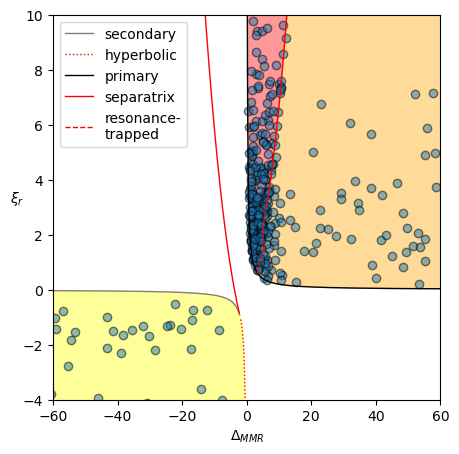

In [18]:
import pandas as pd
from resonantstate.SFMR import *
import matplotlib.pyplot as plt
import f_plots


#load the data
df = pd.read_parquet('data/'+author_name+'_'+simulation_type+'_'+str(run_id))

er_lim=(-4,10)
DMMR_lim=(-60,60)


fig, ax = plt.subplots(1, 1, figsize=(5,5))
ax.scatter(df['DMMR'],df['er'],edgecolors='black',alpha=.5)
plot_topology_DMMR(ax, DMMR_lim, er_lim,dark=False,linewidth=1,legend=True,resonance_trapped=True)
f_plots.plt_area_paper2(ax,DMMR_lim,er_lim,alpha_area=.4)
plt.legend()
